# Airflow and sensible heat recovery

Compare the supported S, F, FT and FTX topologies with explicit air exchange assumptions.

This is an executable lesson about representing building-stock diversity with EPSM Core. All dimensions are metric. The materials, use patterns and stock weights are explicit demonstration assumptions, not calibrated national statistics. Read each explanation before changing the code.

**How to use:** select the **EPSM Core Demo** kernel and Run All from a fresh kernel. Each notebook is independent; generated files go under `output/demo/`. Setup instructions and the complete learning path are in [the demo guide](../README.md).

**Prerequisites:** local EPW, EnergyPlus 24.2.

## Understanding the API in this lesson

`AirflowSpec` separates leakage, natural exchange and mechanical ventilation. The topology codes represent natural ventilation (`S`), mechanical exhaust (`F`), supply/exhaust (`FT`) and supply/exhaust with recovery (`FTX`). Infiltration and natural exchange use air changes per hour; the mechanical rate uses L/(s·m²).

To compare the scales, `ACH × volume / 3600` gives m³/s, while `mechanical_rate × floor_area / 1000` gives m³/s. They need not be equivalent. These prescribed flows enter operations in the workflow; EPSM does not infer wind/stack leakage or fan electricity from the geometry.

Reference: [From observed geometry to an accepted energy comparison](../../docs/figures/workflow.svg). This linked documentation illustration is separate from the outputs computed below.

### Before the first code cell

The setup cell finds the repository, imports the package and plotting tools, and creates a fresh `OUT` directory. `building()` and `geometry()` are **demo input factories**; `table()`, `plans()`, `bars()` and `preview()` are **presentation helpers**, not public `epsm_core` entry points. In particular, `preview()` already displays its output and returns no handle, avoiding duplicate widget display. The public specification and simulation calls remain visible in the lesson cells. Run the setup once per fresh kernel, then follow the cells in order.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/epsm_core").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import json
from dataclasses import asdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from epsm_core import *
from demo.support.common import (building, geometry, epw, engine, workspace, table,
                                 plans, preview, bars, weather_frame, result_frame, result_plots)
from epsm_core.inspection import geometry_scene
OUT = workspace(Path.cwd().name)


## Declare valid topology inputs

Infiltration, natural exchange and mechanical ventilation use different units and represent separate flows. Heat recovery is meaningful only for the compatible system topology.

### Read the code and output

The inputs table makes the unit and topology differences visible before simulation. Recovery effectiveness is a fraction, not a COP. The natural case includes a prescribed ACH, whereas the mechanical cases share an area-based rate; compare them as stated assumption packages rather than identical flows with different names.

,topology,envelope_infiltration_ach,natural_exchange_ach,mechanical_vent_l_s_m2,sensible_recovery_effectiveness,latent_recovery_effectiveness,maximum_heating_supply_temperature_c,minimum_cooling_supply_temperature_c
0,S,0.2,0.3,0.00,0.0,0,50,13
1,F,0.2,0.0,0.35,0.0,0,50,13
2,FT,0.2,0.0,0.35,0.0,0,50,13
3,FTX,0.2,0.0,0.35,0.7,0,50,13


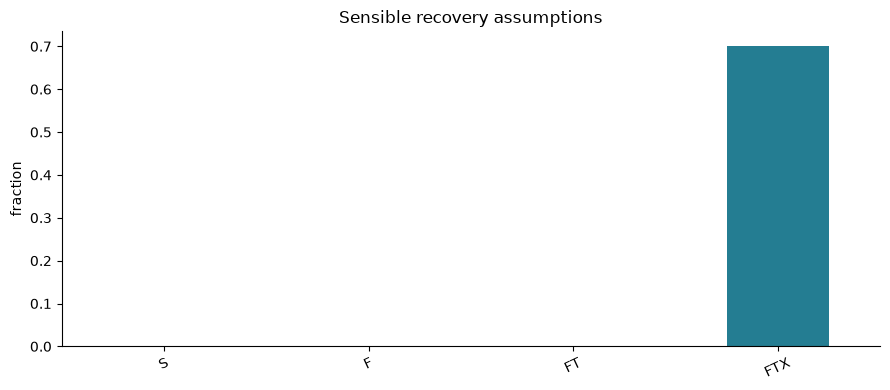

In [2]:
b=building()
flows={"S":AirflowSpec(topology="S",envelope_infiltration_ach=.2,natural_exchange_ach=.3),
       "F":AirflowSpec(topology="F",envelope_infiltration_ach=.2,mechanical_vent_l_s_m2=.35),
       "FT":AirflowSpec(topology="FT",envelope_infiltration_ach=.2,mechanical_vent_l_s_m2=.35),
       "FTX":AirflowSpec(topology="FTX",envelope_infiltration_ach=.2,mechanical_vent_l_s_m2=.35,sensible_recovery_effectiveness=.7)}
table([f.model_dump() for f in flows.values()])
bars({name:f.sensible_recovery_effectiveness for name,f in flows.items()},"fraction","Sensible recovery assumptions")

## Run matched system cases

The natural system is not necessarily flow-equivalent to the mechanical systems. Treat the S comparison as an assumption package; F/FT/FTX keep the mechanical rate fixed.

### Read the code and output

All runs share the building's other inputs. F, FT and FTX therefore isolate compatible mechanical-system assumptions more closely than the natural-versus-mechanical comparison. Inspect accepted diagnostics for each case, and do not infer purchased energy from the heating-demand bars.

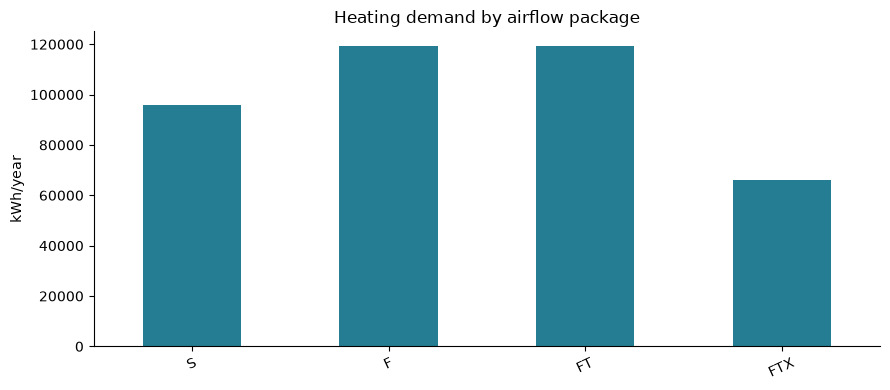

In [3]:
results={name:EnergyPlusRunner(engine()).run(b.updated(airflow=f),OUT/name) for name,f in flows.items()}
bars({name:r.scalars["space_heating_demand_kwh"] for name,r in results.items()},"kWh/year","Heating demand by airflow package")

## Inspect seasonal response

EnergyPlus thermal demand is not automatically purchased heating energy or fan electricity. Only report delivery signals the package actually supplies.

### Read the code and output

Monthly energy can reveal whether a system difference matters mostly during the heating season. It does not report equipment sizing or fan consumption. The acceptance assertion concerns the engine's numerical and output contract, not empirical evidence that the assumed airflow occurs in real buildings.

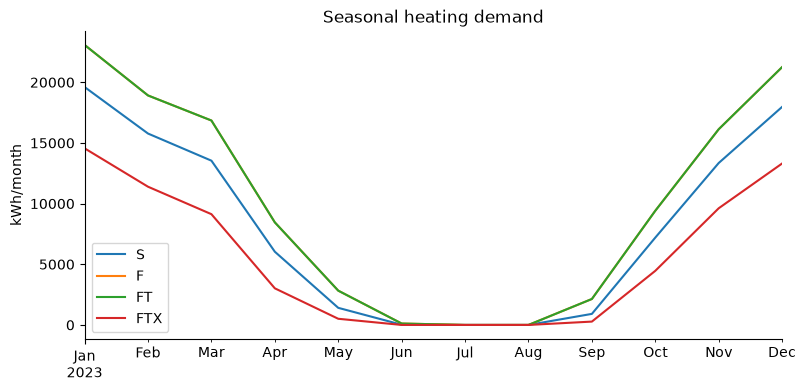

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
pd.DataFrame({name:result_frame(r).space_heating_demand_kwh.resample("ME").sum() for name,r in results.items()}).plot(ax=ax, ylabel="kWh/month",title="Seasonal heating demand"); plt.show(); plt.close(fig)
assert all(r.diagnostics["accepted"] for r in results.values())

## Interpretation and next experiment

Record assumed ventilation rates and recovery efficiency independently. A national stock needs evidence for both system prevalence and actual operation.

For a stock study, retain the inputs, provenance and acceptance decisions with every result. A successful geometry preview does not establish simulation validity or predictive accuracy. Change one assumption at a time before combining measures, and report rejected or substituted cases alongside accepted cases.